# Cost Variance Validation: NSOSA Constellations

Architecture studies of satellite constellations compare alternatives whose costs are uncertain and correlated: alternatives that share a satellite design share its cost risk. Maier, Yeakel, and Wendoloski ("Cost Variance Analysis in Constellation Architecture Studies," *IEEE Systems Journal* 17(2), 1928–1938, 2023, [doi:10.1109/JSYST.2022.3218598](https://doi.org/10.1109/JSYST.2022.3218598)) model the uncertain cost of each satellite configuration from the growth of its components by their maturity (the formal risk assessment of system cost estimates, FRISK). They extend it to constellations whose configurations are produced in blocks over decades, and work through two constellations of the NOAA Satellite Observing System Architecture (NSOSA) study that share a geostationary configuration, whose order of cost depends on what they share. TAT-C's `tradespace` module models the same structure: the growth of components by maturity (`Triangular`, `Component`), correlated within a cost model (`CostModel.correlation`); types of satellites produced in blocks (`SatelliteCost.block_size`); deployments from launch schedules (`DeploymentSchedule`); and scores of the cost risk drawn as uncertain parameters (`risk_space`, `CostModel.draw`), which common random numbers share between the designs of a `Study`, compared with `exceedance`. This notebook reproduces the paper's example and asks:

1. **Growth by maturity.** Do `Triangular` growths reproduce the cost growth factors of Table I, and does `CostModel.correlation` reproduce the variance of a configuration of correlated components (eq. 2)?
2. **Production blocks.** Does `DeploymentSchedule` reproduce the launches and production blocks of the configurations from their launch schedules (Tables II and III), and does `CostModel.estimate` count the developments, first units, and later units of each constellation over the study period (matrix *B* of eq. 5)?
3. **Constellation costs.** Do the replicates of a `Study` reproduce the means, variances, and covariance of the costs of the two constellations (eqs. 6 and 8, Fig. 2)?
4. **Order of costs.** Does `exceedance` reproduce the probability that one constellation costs more than the other (eqs. 9 to 15, Fig. 3), and how much of it comes from the configuration they share?

The paper's other results are not reproduced. Its efficient frontier and rank-swap matrix of NSOSA constellations (Figs. 1 and 4) need costs of constellations that were not published, and its comparison with the GOES-R and JPSS programs (Figs. 5 and 6) needs the Aerospace Concept Design Center's cost models and the programs' historical costs. Costs are relative, as in the paper: multiples of the annual cost of the least expensive NSOSA constellation.

## Reference Data

The reference values are those published in the paper:

* **Table I** gives the cost growth factors of components by maturity (new, major modification, modified, minor modification, and existing): the lowest, most likely (1), and highest growth of a triangular distribution, and its mean.
* **Table II** gives the configurations of the two constellations. C1 flies the geostationary configuration G4c (an advanced GOES-R) on a 48-month launch schedule from April 2029, and the large low Earth orbit (LEO) configuration L3e every 54 months from July 2032. C2 flies G4c every 32 months from April 2029, and the smaller LEO configuration L4f "46 (x2) months" from July 2028, read here as two satellites every 46 months. Each configuration is produced in blocks of four satellites.
* **Eq. (5)** gives the matrix *A* of the shares of a block's cost in its development (Dev), the production and launch of its first unit (T1), and of each later unit (Ta), and the matrix *B* of the number of each in each constellation from 2020 to the end of September 2050 (Table III shows how G4c's numbers in C1 are counted).
* **Eqs. (6) and (7)** give the expected cost of a block of each configuration, E[*Q*], and its variance (*R*), uncorrelated between configurations. The variances are in millionths of the squared relative cost: the standard deviation of a block of G4c is 0.0997.

From these, the expected costs of the constellations are E[*C*] = *BA* E[*Q*] (eq. 6) and their covariance *BARA*ᵀ*B*ᵀ (eq. 8). The probability that C2 costs more than C1 is the integral of their bivariate normal distribution above the line *y* = *x* (eq. 15), computed here both numerically and in closed form (the normal probability of the mean difference over the standard deviation of the difference). The published results are the expected costs and standard deviations (eq. 6 and Fig. 2), the covariance matrix (eq. 8), and the probability (Fig. 3).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, stats

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#8a8a86", "#2b2b29"

# Table I: the lowest and highest cost growth factors of components by maturity (most likely 1), and their mean
TABLE_I = pd.DataFrame(
    {
        "low": [0.827, 0.864, 0.904, 0.943, 0.981],
        "high": [2.274, 1.993, 1.708, 1.423, 1.140],
        "mean": [1.367, 1.286, 1.204, 1.122, 1.041],
    },
    index=pd.Index(
        ["new", "major modification", "modified", "minor modification", "existing"],
        name="maturity",
    ),
)
# eq. (5), matrix A: the shares of the cost of a block in its development, first unit, and each later unit
SHARES = {
    "G4c": (0.309, 0.132, 0.115),
    "L3e": (0.290, 0.126, 0.110),
    "L4f": (0.217, 0.054, 0.047),
}
# eq. (6): the expected cost of a block, E[Q]; eq. (7): its variance, R (published in millionths)
MEAN_Q = {"G4c": 3.33, "L3e": 3.14, "L4f": 1.61}
VARIANCE_Q = {"G4c": 9930e-6, "L3e": 71900e-6, "L4f": 5260e-6}
# eq. (5), matrix B: the developments, first units, and later units of each configuration of each constellation
PUBLISHED = {
    "C1": {"G4c": (2, 2, 4.37), "L3e": (2, 2, 3)},
    "C2": {"G4c": (3, 3, 6.37), "L4f": (2.9, 2.9, 10.8)},
}
CONSTELLATIONS = list(PUBLISHED)
CONFIGURATIONS = list(MEAN_Q)


def exposures(counts):
    """The matrix BA: the multiple of the cost of a block of each configuration in each constellation."""
    return np.array(
        [
            [np.dot(counts[name].get(c, (0, 0, 0)), SHARES[c]) for c in CONFIGURATIONS]
            for name in CONSTELLATIONS
        ]
    )


def moments(counts, correlated=True):
    """The expected costs of the constellations (eq. 6) and their covariance (eq. 8), or only their variances."""
    ba = exposures(counts)
    mean = ba @ np.array([MEAN_Q[c] for c in CONFIGURATIONS])
    covariance = ba @ np.diag([VARIANCE_Q[c] for c in CONFIGURATIONS]) @ ba.T
    return mean, covariance if correlated else np.diag(np.diag(covariance))


def probability_exceeds(mean, covariance):
    """The probability that the second cost exceeds the first: eq. (15) integrated numerically, and in closed form."""
    sx, sy = np.sqrt(np.diag(covariance))
    rho = covariance[0, 1] / (sx * sy)
    sigma = sy * math.sqrt(1 - rho**2)  # eq. (12)

    def integrand(x):
        mu = mean[1] + sy / sx * rho * (x - mean[0])  # eq. (11)
        return stats.norm.pdf(x, mean[0], sx) * stats.norm.sf(x, mu, sigma)

    numerical = integrate.quad(integrand, mean[0] - 12 * sx, mean[0] + 12 * sx)[0]
    spread = math.sqrt(covariance[0, 0] + covariance[1, 1] - 2 * covariance[0, 1])
    return numerical, stats.norm.cdf((mean[1] - mean[0]) / spread)


mean, covariance = moments(PUBLISHED)
numerical, closed = probability_exceeds(mean, covariance)
independent = probability_exceeds(*moments(PUBLISHED, correlated=False))[1]
reference = pd.DataFrame(
    {
        "published": [8.27, 8.93, 0.34, 0.23, 116118, 28260, 50757, 0.978],
        "from the published inputs": [
            *mean,
            *np.sqrt(np.diag(covariance)),
            covariance[0, 0] * 1e6,
            covariance[0, 1] * 1e6,
            covariance[1, 1] * 1e6,
            numerical,
        ],
    },
    index=[
        "E[C1]",
        "E[C2]",
        "std C1",
        "std C2",
        "var C1 (millionths)",
        "cov C1, C2 (millionths)",
        "var C2 (millionths)",
        "P(C2 > C1)",
    ],
)
print(
    f"P(C2 > C1): {numerical:.4f} by eq. (15), {closed:.4f} in closed form; "
    + f"{independent:.4f} if the costs were independent"
)
reference.round(4)

P(C2 > C1): 0.9779 by eq. (15), 0.9779 in closed form; 0.9491 if the costs were independent


,published,from the published inputs
E[C1],8.270,8.2592
E[C2],8.930,8.9275
std C1,0.340,0.3408
std C2,0.230,0.2253
var C1 (millionths),116118.000,116118.1421
"cov C1, C2 (millionths)",28260.000,28260.8967
var C2 (millionths),50757.000,50757.8163
P(C2 > C1),0.978,0.9779


The published inputs reproduce the published results, within the rounding of *A*'s shares: expected costs of 8.26 and 8.93 (eq. 6 gives 8.27 and 8.93, and Fig. 2 gives 8.27 and 8.94), standard deviations of 0.34 and 0.23, the covariance matrix of eq. (8) within one millionth, and a probability of 97.8% that C2 costs more than C1 (eq. 15, equal to the closed form). If the costs of the two constellations were independent, the probability would be 94.9%: the shared configuration G4c makes the order more certain.

## Test 1: Growth by Maturity

FRISK models the growth of the cost of each component as a triangular distribution from a low to a high multiple of its point estimate, most likely the estimate itself. The spread and skew grow as the component's maturity falls (Table I). The variance of each component is that of its triangular distribution (eq. 1), and the variance of a configuration is the sum of the covariances of its components, correlated by 0.5 (eq. 2). In TAT-C, `Triangular(low, high)` gives the distribution (most likely 1), and a `Component` grows by it. A `CostModel` with `correlation=0.5` draws the growths of its components from standard normal scores mixed with a common score (`CostModel.draw`): the growth of each component is the quantile of its distribution at the normal probability of `sqrt(0.5) * common + sqrt(0.5) * own`, so that the scores of every pair of components are correlated by 0.5. The scores are uncertain parameters of a design space (`risk_space`), drawn in each replicate of a `Study`.

The paper gives no component costs of its configurations, so eq. (2) is checked for a configuration of one component of each maturity with equal point estimates (1), in 20,000 replicates. The correlation of the growths themselves is computed exactly (by Gauss–Hermite quadrature over the bivariate normal scores) as well as from the replicates. The standard deviations of Table I's distributions are compared with SciPy's triangular distribution, an independent implementation.

In [2]:
from scipy import optimize

from tatc.tradespace import (
    Component,
    CostModel,
    DesignSpace,
    SatelliteCost,
    Study,
    Triangular,
    risk_space,
)

GROWTH = {name: Triangular(row.low, row.high) for name, row in TABLE_I.iterrows()}
CORRELATION = 0.5  # of the scores of the components (eq. 2 assumes it of their costs)
REPLICATES = 20_000

# a configuration of one component of each maturity, with equal point estimates
mixed = CostModel(
    SatelliteCost(
        components=[
            Component(name, development=1.0, growth=g) for name, g in GROWTH.items()
        ]
    ),
    correlation=CORRELATION,
)
mixed_space = DesignSpace(cost_risk=risk_space(mixed))


def growths(_, design):
    """The growth of each component, drawn from the replicate's scores, and of the configuration."""
    drawn = mixed.draw(design.cost_risk)
    values = {c.name: c.growth for c in drawn.satellites.components}
    return {**values, "configuration": sum(values.values())}


draws = Study(mixed_space, lambda d: None, growths, replicates=REPLICATES).run(
    mixed_space.enumerate()
)


def growth_correlation(a, b, rho, nodes=200):
    """The correlation of the growths of two components whose scores are correlated by rho (Gauss-Hermite)."""
    z, w = np.polynomial.hermite_e.hermegauss(nodes)
    w = np.outer(w, w) / w.sum() ** 2
    za, zb = np.meshgrid(z, z, indexing="ij")
    ga = np.vectorize(a.ppf)(stats.norm.cdf(za))
    gb = np.vectorize(b.ppf)(stats.norm.cdf(rho * za + math.sqrt(1 - rho**2) * zb))
    return np.sum(w * (ga - a.mean()) * (gb - b.mean())) / (a.std() * b.std())


table1 = TABLE_I.assign(
    **{
        "TAT-C mean": [g.mean() for g in GROWTH.values()],
        "mean of replicates": draws[list(GROWTH)].mean().to_numpy(),
        "std (SciPy)": [
            stats.triang((1 - g.low) / (g.high - g.low), g.low, g.high - g.low).std()
            for g in GROWTH.values()
        ],
        "TAT-C std": [g.std() for g in GROWTH.values()],
        "std of replicates": draws[list(GROWTH)].std().to_numpy(),
        "mode (share of range)": [
            (1 - g.low) / (g.high - g.low) for g in GROWTH.values()
        ],
    }
)
pairs = [(a, b) for i, a in enumerate(GROWTH) for b in list(GROWTH)[i + 1 :]]
exact = [growth_correlation(GROWTH[a], GROWTH[b], CORRELATION) for a, b in pairs]
sampled = [draws[a].corr(draws[b]) for a, b in pairs]
sigma = np.array([g.std() for g in GROWTH.values()])
off_diagonal = sigma.sum() ** 2 - (sigma**2).sum()  # twice the sum of products of pairs
eq2 = (sigma**2).sum() + CORRELATION * off_diagonal
eq2_exact = (sigma**2).sum() + np.mean(exact) * off_diagonal
matching = optimize.brentq(
    lambda rho: growth_correlation(GROWTH["new"], GROWTH["existing"], rho) - 0.5,
    0.4,
    0.7,
)
print(
    f"correlation of growths: {min(exact):.4f} to {max(exact):.4f} exactly, "
    + f"{min(sampled):.3f} to {max(sampled):.3f} in the replicates (10 pairs)"
)
print(
    f"variance of the configuration: {eq2:.4f} by eq. (2), {draws.configuration.var():.4f} in the replicates "
    + f"({draws.configuration.var() / eq2 - 1:+.1%}), {eq2_exact:.4f} by eq. (2) with the exact correlation"
)
print(f"correlation of scores that correlates growths by 0.5: {matching:.4f}")
table1.round(4)

correlation of growths: 0.4862 to 0.4862 exactly, 0.488 to 0.502 in the replicates (10 pairs)
variance of the configuration: 0.5075 by eq. (2), 0.5008 in the replicates (-1.3%), 0.4994 by eq. (2) with the exact correlation
correlation of scores that correlates growths by 0.5: 0.5139


,low,high,mean,TAT-C mean,mean of replicates,std (SciPy),TAT-C std,std of replicates,mode (share of range)
maturity,,,,,,,,,
new,0.827,2.274,1.367,1.3670,1.3636,0.3226,0.3226,0.3219,0.1196
major modification,0.864,1.993,1.286,1.2857,1.2842,0.2516,0.2516,0.2515,0.1205
modified,0.904,1.708,1.204,1.2040,1.2028,0.1793,0.1793,0.1789,0.1194
minor modification,0.943,1.423,1.122,1.1220,1.1220,0.1071,0.1071,0.1072,0.1188
existing,0.981,1.140,1.041,1.0403,1.0400,0.0355,0.0355,0.0355,0.1195


`Triangular` reproduces Table I: its means equal the published means to the table's three decimals for four of the five maturities. The fifth, existing components, is 1.0403 against the published 1.041; the mean of (0.981, 1, 1.140) is 1.0403, so the table's last digit is rounded up. Its standard deviations equal SciPy's, and the replicates drawn through `CostModel.draw` reproduce the means and standard deviations within their sampling errors (at most 0.0023 for the means).

`CostModel.correlation` correlates the scores of components, not their growths: the quantile transform of a skewed distribution lowers the correlation of the growths to 0.486 for every pair. Table I's distributions all have the same shape (the most likely growth at 12% of each one's range), so all pairs are lowered alike. The replicates give 0.488 to 0.502, within their sampling error of about 0.006. The configuration's variance is 1.3% below eq. (2), as eq. (2) with the exact correlation predicts. A correlation of the scores of 0.514 gives growths correlated by 0.5, as eq. (2) assumes. This difference is small next to the uncertainty of the correlation itself, which the paper puts at 0.5 as "generally appropriate."

## Test 2: Production Blocks

The paper costs each configuration over 2020 to 2050 in blocks of four satellites. Each block is a new design, whose development (Dev) and first unit (T1) are paid again, followed by three later units (Ta). In TAT-C, a type of satellite with `block_size=4` (and `redevelopment=1`, a full redesign) develops each block after the first before the production of the block's first unit, over the type's development time (see `CostModel.estimate`).

A `DeploymentSchedule` plans the deployment of each constellation, with the design life, development time, and production rate of each configuration (mappings by kind):

* **Launches.** A design life equal to a configuration's launch interval launches a replacement at that interval from its first launch.
* **Production.** Each launch's satellites are produced over the four years before it, as Table III's later units are.
* **Development.** Development runs from the start (1 March 2020, when Table III begins G4c's first development) to the production of the first unit.
* **Study period.** The mission ends at the end of September 2050, and the constellation is `sustained`: replaced after the end as before it. The units in production at the end are then produced (though not launched in the mission), and the costs of the deployment are those incurred by the end, which count each development and each unit by the share done (see `CostModel.estimate`).

The layout of a configuration is its slots: a subclass of `Layout`, which needs only its planes to be deployed and costed (the orbits matter only to build the satellites).

In [3]:
from tatc.tradespace import DeploymentSchedule
from tatc.tradespace.constellations import Layout, Plane

BLOCK_SIZE = 4
PRODUCTION_YEARS = 4  # the production of each launch's satellites (Table III)
MONTHS = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()


def year(y, m):
    """The start of a month, in years from 1 March 2020."""
    return y - 2020 + (m - 3) / 12


def month(time):
    """The month of a time, in years from 1 March 2020."""
    months = round(time * 12) + 2
    return f"{MONTHS[months % 12]} {2020 + months // 12}"


END = year(2050, 10)  # the end of September 2050
# Table II: the first launch, the months between launches, and the satellites of each launch
SCHEDULES = {
    "C1": {"G4c": (year(2029, 4), 48, 1), "L3e": (year(2032, 7), 54, 1)},
    "C2": {"G4c": (year(2029, 4), 32, 1), "L4f": (year(2028, 7), 46, 2)},
}


class Slots(Layout):
    """Orbital slots, whose satellites are launched together (one plane, for deployments)."""

    def __init__(self, count):
        self.count = count

    def planes(self):
        return [Plane(self.count)]


def plan(name, sustained=True):
    """The deployment of a constellation: each configuration launched at its interval from its first launch."""
    configurations = SCHEDULES[name]
    schedule = DeploymentSchedule(
        years=END - min(first for first, _, _ in configurations.values()),
        design_life={c: months / 12 for c, (_, months, _) in configurations.items()},
        development_years={
            c: first - PRODUCTION_YEARS for c, (first, _, _) in configurations.items()
        },
        production_rate={
            c: satellites / PRODUCTION_YEARS
            for c, (_, _, satellites) in configurations.items()
        },
        sustained=sustained,
    )
    return schedule.plan(
        {c: Slots(satellites) for c, (_, _, satellites) in configurations.items()}
    )


DEPLOYMENTS = {name: plan(name) for name in SCHEDULES}
for name, deployment in DEPLOYMENTS.items():
    for c in SCHEDULES[name]:
        launches = [l.time for l in deployment.launches if l.kind == c]
        print(f"{name} {c}: launches in", ", ".join(month(t) for t in launches))


def shares_produced(deployment, configuration):
    """The share of each unit of a configuration produced by the end, in the order of production."""
    shares = []
    for batch in deployment.production:
        if batch.kind == configuration:
            done = (END - batch.begin) / (batch.end - batch.begin)
            shares += [min(max(done, 0.0), 1.0)] * batch.satellites
    return shares


# Table III: G4c in C1 (the start of development of each block, and of production and launch of each unit)
TABLE_III = pd.DataFrame(
    [
        ("Mar 2020", "Sep 2023", "Apr 2029", 1.0),
        (None, "Apr 2029", "Apr 2033", 1.0),
        (None, "Apr 2033", "Apr 2037", 1.0),
        (None, "Apr 2037", "Apr 2041", 1.0),
        ("Mar 2036", "Sep 2039", "Apr 2045", 1.0),
        (None, "Apr 2045", "Apr 2049", 1.0),
        (None, "Apr 2049", "Apr 2053", 0.37),
    ],
    columns=["development", "production", "launch", "counted"],
)
c1 = DEPLOYMENTS["C1"]
developed = c1.development["G4c"]
# the units of G4c in production by the end, including the one launched after it
batches = [b for b in c1.production if b.kind == "G4c" and b.begin < END]
table3 = []
for unit, (batch, share) in enumerate(zip(batches, shares_produced(c1, "G4c"))):
    first = unit % BLOCK_SIZE == 0
    table3.append(
        {
            "unit": f"block {unit // BLOCK_SIZE + 1}, unit {unit % BLOCK_SIZE + 1}",
            # each block's development ends as the production of its first unit begins
            "TAT-C development": (
                month(max(batch.begin - developed, 0)) if first else None
            ),
            "TAT-C production": month(batch.begin),
            "TAT-C launch": month(batch.end),  # each unit is produced until its launch
            "TAT-C counted": share,
        }
    )
table3 = pd.DataFrame(table3).join(TABLE_III.add_prefix("paper ")).set_index("unit")
table3[[f"{side} {column}" for column in TABLE_III for side in ("paper", "TAT-C")]]

C1 G4c: launches in Apr 2029, Apr 2033, Apr 2037, Apr 2041, Apr 2045, Apr 2049
C1 L3e: launches in Jul 2032, Jan 2037, Jul 2041, Jan 2046, Jul 2050
C2 G4c: launches in Apr 2029, Dec 2031, Aug 2034, Apr 2037, Dec 2039, Aug 2042, Apr 2045, Dec 2047, Aug 2050
C2 L4f: launches in Jul 2028, May 2032, Mar 2036, Jan 2040, Nov 2043, Sep 2047


,paper development,TAT-C development,paper production,TAT-C production,paper launch,TAT-C launch,paper counted,TAT-C counted
unit,,,,,,,,
"block 1, unit 1",Mar 2020,Mar 2020,Sep 2023,Apr 2025,Apr 2029,Apr 2029,1.00,1.000
"block 1, unit 2",None,None,Apr 2029,Apr 2029,Apr 2033,Apr 2033,1.00,1.000
"block 1, unit 3",None,None,Apr 2033,Apr 2033,Apr 2037,Apr 2037,1.00,1.000
"block 1, unit 4",None,None,Apr 2037,Apr 2037,Apr 2041,Apr 2041,1.00,1.000
"block 2, unit 1",Mar 2036,Mar 2036,Sep 2039,Apr 2041,Apr 2045,Apr 2045,1.00,1.000
"block 2, unit 2",None,None,Apr 2045,Apr 2045,Apr 2049,Apr 2049,1.00,1.000
"block 2, unit 3",None,None,Apr 2049,Apr 2049,Apr 2053,Apr 2053,0.37,0.375


TAT-C's deployment of G4c in C1 reproduces Table III's launches, the production of its later units, and the starts of development of both blocks (March 2020 and March 2036). With development ending as production begins, the second block's development takes the 5.1 years before its first unit's production (April 2041), which starts it in March 2036, as Table III does. Table III's Phases B and C start the first unit's production earlier (September 2023, 5.6 years before launch), where TAT-C produces every unit over four years: the dates of the first units' costs differ, not their amounts. The sustained deployment produces the unit launched in April 2053 from April 2049: 18 of its 48 months by the end of September 2050, or 0.375 of it (Table III's 0.37).

TAT-C's estimate counts the developments and units of a configuration as costs. A model that costs 1 for each development and each unit of one configuration (and nothing for the others) gives the number of developments, *D*, and of units, *U*, each counted by the share done by the end. With each block's first-unit premium (T1 − Ta) charged with its development, as Test 3 costs the configurations, these cost as *D* developments and first units and *U* − *D* later units, the form of *B*. The counts of each constellation are below, together with two alternatives: TAT-C's dates counted as Table III counts them (each block's development with the share of its first unit produced), and a mission that is not sustained, whose costs are those of the units it launches by its end.

In [4]:
def counted(deployment, configuration):
    """The developments and units of a configuration that TAT-C's estimate costs, as (Dev, T1, Ta)."""
    each = SatelliteCost(development=1.0, first_unit=1.0, block_size=BLOCK_SIZE)
    model = CostModel(
        {
            c: each if c == configuration else SatelliteCost()
            for c in deployment.development
        }
    )
    estimate = model.estimate(deployment)
    return (
        estimate.development,
        estimate.development,
        estimate.production - estimate.development,
    )


def counted_as_table_iii(deployment, configuration):
    """The developments, first units, and later units by the end, as Table III counts them."""
    shares = shares_produced(deployment, configuration)
    first = sum(
        shares[::BLOCK_SIZE]
    )  # each block's development is counted with its first unit
    return (first, first, sum(shares) - first)


COUNTS = {
    "paper": PUBLISHED,
    "TAT-C, study period": {},
    "TAT-C's dates, counted as Table III": {},
    "TAT-C, mission": {},
}
for name, configurations in SCHEDULES.items():
    ending = plan(name, sustained=False)
    COUNTS["TAT-C, study period"][name] = {
        c: counted(DEPLOYMENTS[name], c) for c in configurations
    }
    COUNTS["TAT-C's dates, counted as Table III"][name] = {
        c: counted_as_table_iii(DEPLOYMENTS[name], c) for c in configurations
    }
    COUNTS["TAT-C, mission"][name] = {c: counted(ending, c) for c in configurations}
rows = [
    {
        "constellation": name,
        "configuration": c,
        "count": key,
        **dict(zip(["Dev", "T1", "Ta"], values)),
        "expected cost": MEAN_Q[c] * np.dot(values, SHARES[c]),
    }
    for key, counts in COUNTS.items()
    for name, configurations in counts.items()
    for c, values in configurations.items()
]
counts = (
    pd.DataFrame(rows)
    .set_index(["constellation", "configuration", "count"])
    .sort_index()
)
totals = []
for key, table in COUNTS.items():
    mean, covariance = moments(table)
    totals.append(
        {
            "count": key,
            "E[C1]": mean[0],
            "E[C2]": mean[1],
            "E[C2] - E[C1]": mean[1] - mean[0],
            "P(C2 > C1)": probability_exceeds(mean, covariance)[1],
        }
    )
display(counts.round(4))
pd.DataFrame(totals).set_index("count").round(4)

Dev  \
constellation configuration count                                         
C1            G4c           TAT-C's dates, counted as Table III  2.0000   
                            TAT-C, mission                       2.0000   
                            TAT-C, study period                  2.0000   
                            paper                                2.0000   
              L3e           TAT-C's dates, counted as Table III  2.0000   
                            TAT-C, mission                       2.0000   
                            TAT-C, study period                  2.0000   
                            paper                                2.0000   
C2            G4c           TAT-C's dates, counted as Table III  3.0000   
                            TAT-C, mission                       3.0000   
                            TAT-C, study period                  3.0000   
                            paper                                3.0000   
              L4f           TAT-C's dates, counted as Table III  3.8125   
                            TAT-C, mission                       3.0000   
                            TAT-C, study period                  4.0000   
                            paper                                2.9000   

                                                                     T1  \
constellation configuration count                                         
C1            G4c           TAT-C's dates, counted as Table III  2.0000   
                            TAT-C, mission                       2.0000   
                            TAT-C, study period                  2.0000   
                            paper                                2.0000   
              L3e           TAT-C's dates, counted as Table III  2.0000   
                            TAT-C, mission                       2.0000   
                            TAT-C, study period                  2.0000   
                            paper                                2.0000   
C2            G4c           TAT-C's dates, counted as Table III  3.0000   
                            TAT-C, mission                       3.0000   
                            TAT-C, study period                  3.0000   
                            paper                                3.0000   
              L4f           TAT-C's dates, counted as Table III  3.8125   
                            TAT-C, mission                       3.0000   
                            TAT-C, study period                  4.0000   
                            paper                                2.9000   

                                                                      Ta  \
constellation configuration count                                          
C1            G4c           TAT-C's dates, counted as Table III   4.3750   
                            TAT-C, mission                        4.0000   
                            TAT-C, study period                   4.3750   
                            paper                                 4.3700   
              L3e           TAT-C's dates, counted as Table III   3.0000   
                            TAT-C, mission                        3.0000   
                            TAT-C, study period                   3.0000   
                            paper                                 3.0000   
C2            G4c           TAT-C's dates, counted as Table III   6.3750   
                            TAT-C, mission                        6.0000   
                            TAT-C, study period                   6.3750   
                            paper                                 6.3700   
              L4f           TAT-C's dates, counted as Table III   9.8125   
                            TAT-C, mission                        9.0000   
                            TAT-C, study period                   9.6250   
                            paper                                10.8000  

,E[C1],E[C2],E[C2] - E[C1],P(C2 > C1)
count,,,,
paper,8.2592,8.9275,0.6683,0.9779
"TAT-C, study period",8.2611,9.3205,1.0593,0.9991
"TAT-C's dates, counted as Table III",8.2611,9.2528,0.9917,0.9984
"TAT-C, mission",8.1175,8.6933,0.5757,0.9590


Over the study period, TAT-C's estimates reproduce the published numbers of G4c in both constellations (2, 2, 4.375 and 3, 3, 6.375 against 4.37 and 6.37) and of L3e (2, 2, 3), and so C1's expected cost (8.2611 against 8.2592, the difference being the rounding of 4.375). The published numbers of L4f (2.9 developments and first units, 10.8 later units) cannot be derived from its schedule. Its six launches of two satellites before the end (12 units, 3 blocks), and the 0.81 of the next two produced, give about the same units (13.6 against 13.7) but more developments. TAT-C counts 4, as the fourth block is developed from March 2043 until its first unit's production begins in July 2047, before the end. Table III's count, which counts that development with the 0.81 of its first unit, gives 3.81. Two satellites per launch every 46 months is one reading of Table II's "46 (x2)". Other readings, such as two slots with blocks of their own (4 developments) or one launch every 23 months (3.81), do not give 2.9 either. With TAT-C's counts, L4f costs 0.39 more than with its published counts, and the probability that C2 costs more than C1 is 99.9% (99.8% with Table III's count).

A mission that is not sustained costs the units it launches by its end. It leaves out the 0.375 of a G4c unit in production at the end in both constellations (0.14 of each one's cost) and L4f's fourth block, whose units are launched after the end. Both constellations then cost less (8.12 and 8.69), and the probability that C2 costs more is 95.9%: nearer the paper's 97.8%, but only because its cost of L4f (1.99) happens to be nearer the published one (2.08). The tests below evaluate the costs of the published numbers, to test TAT-C's cost risk on the paper's inputs, and also TAT-C's own estimates of the deployments over the study period.

## Test 3: Constellation Costs

The paper's cost of a block of a configuration is a random variable *Q* (normal, from its FRISK estimate), of which fixed shares are its development, first unit, and each later unit: every element of every block grows with *Q*. In TAT-C, each configuration is a type of satellite with one component (named after it) whose growth is normal, with mean 1 and the standard deviation of *Q* relative to its mean. The growth is a SciPy distribution, which has the `ppf` and `mean` that a `Component` needs. Without learning (the default learning rate of 1), each unit costs the component's `first_unit`, here the cost of a later unit (Ta). The first unit's premium (T1 - Ta) is charged with each block's development, so that a block costs Dev + T1 + 3 Ta, as in the paper. (A learning curve would also give the premium: Ta/T1 is about 0.87 for all three configurations, the mean of units 2 to 4 on a 91% curve, but the paper charges every later unit the same.) The growths of the configurations are uncorrelated (`correlation=0`, the default), as the paper assumes, so the scores of the cost risk are those of G4c, L3e, and L4f (`risk_space`).

The design space has one design variable, the constellation (C1 or C2), and the scores. Two evaluations of the replicates are compared:

* **Published counts.** The cost of the published numbers of developments and units (*B*): each block costs the `total_development` and each unit the `total_first_unit` of the configuration drawn from the replicate's scores. This tests TAT-C's cost risk on the paper's inputs.
* **TAT-C deployments.** TAT-C's own estimate (`CostModel.estimate`) of the sustained deployments of Test 2, over the study period.

Each runs 20,000 replicates with common random numbers (the default), in which both constellations draw the same scores, and 20,000 with independent draws (for Test 4).

In [5]:
from tatc.tradespace import Categorical

TYPES = {
    c: SatelliteCost(
        components=[
            Component(
                c,
                development=(dev + first - later) * MEAN_Q[c],
                first_unit=later * MEAN_Q[c],
                growth=stats.norm(1, math.sqrt(VARIANCE_Q[c]) / MEAN_Q[c]),
            )
        ],
        block_size=BLOCK_SIZE,
    )
    for c, (dev, first, later) in SHARES.items()
}
MODEL = CostModel(TYPES)
space = DesignSpace(
    constellation=Categorical(CONSTELLATIONS), cost_risk=risk_space(MODEL)
)
designs = space.enumerate()
print("scores:", space.uncertain_paths())
# the expected costs of TAT-C's deployments (with the components' mean growth), against the counts of Test 2
for name, deployment in DEPLOYMENTS.items():
    estimate = MODEL.estimate(deployment)
    expected = moments(COUNTS["TAT-C, study period"])[0][CONSTELLATIONS.index(name)]
    print(
        f"{name}: blocks begun {estimate.blocks}, units begun {estimate.units}, "
        + f"expected cost {estimate.total:.4f} ({expected:.4f} from the counts of Test 2)"
    )


def build(design):
    return design.constellation


def published(constellation, design):
    """The cost of the published numbers of developments and units, drawn in the replicate."""
    drawn = MODEL.draw(design.cost_risk)
    cost = 0.0
    for c, (developments, first, later) in PUBLISHED[constellation].items():
        configuration = drawn.satellites[c]
        # developments and first units are counted alike: each block costs Dev + T1 - Ta, and each unit Ta
        cost += developments * configuration.total_development
        cost += (first + later) * configuration.total_first_unit
    return {"cost": cost}


def deployed(constellation, design):
    """TAT-C's estimate of the cost of the constellation's deployment, drawn in the replicate."""
    drawn = MODEL.draw(design.cost_risk)
    return {"cost": drawn.estimate(DEPLOYMENTS[constellation]).total}


EVALUATIONS = {
    "published counts": (published, PUBLISHED),
    "TAT-C deployments": (deployed, COUNTS["TAT-C, study period"]),
}
results = {
    (name, draws): Study(
        space,
        build,
        evaluate,
        replicates=REPLICATES,
        common_random_numbers=draws == "common",
    ).run(designs)
    for name, (evaluate, _) in EVALUATIONS.items()
    for draws in ("common", "independent")
}
wide = {
    key: frame.pivot(index="replicate", columns="constellation", values="cost")
    for key, frame in results.items()
}


def statistics(mean, covariance):
    std = np.sqrt(np.diag(covariance))
    return {
        "E[C1]": mean[0],
        "E[C2]": mean[1],
        "std C1": std[0],
        "std C2": std[1],
        "cov (millionths)": covariance[0, 1] * 1e6,
        "correlation": covariance[0, 1] / (std[0] * std[1]),
    }


rows = {
    "paper (eqs. 6 and 8)": statistics(
        [8.27, 8.93], np.array([[116118, 28260], [28260, 50757]]) * 1e-6
    )
}
for name, (_, table) in EVALUATIONS.items():
    rows[f"{name}: expected"] = statistics(*moments(table))
    sample = wide[name, "common"]
    rows[f"{name}: replicates"] = statistics(
        sample.mean().to_numpy(), np.cov(sample.to_numpy().T)
    )
print(
    f"standard errors of the means of the replicates: {wide['published counts', 'common'].std().max() / math.sqrt(REPLICATES):.4f}"
)
pd.DataFrame(rows).T.round(4)

scores: ['cost_risk.G4c', 'cost_risk.L3e', 'cost_risk.L4f']
C1: blocks begun {'G4c': 2, 'L3e': 2}, units begun {'G4c': 7, 'L3e': 5}, expected cost 8.2611 (8.2611 from the counts of Test 2)
C2: blocks begun {'L4f': 4, 'G4c': 3}, units begun {'L4f': 14, 'G4c': 10}, expected cost 9.3205 (9.3205 from the counts of Test 2)


standard errors of the means of the replicates: 0.0024


,E[C1],E[C2],std C1,std C2,cov (millionths),correlation
paper (eqs. 6 and 8),8.2700,8.9300,0.3408,0.2253,28260.0000,0.3681
published counts: expected,8.2592,8.9275,0.3408,0.2253,28260.8967,0.3681
published counts: replicates,8.2622,8.9269,0.3401,0.2241,27968.4192,0.3669
TAT-C deployments: expected,8.2611,9.3205,0.3408,0.2332,28280.5421,0.3558
TAT-C deployments: replicates,8.2641,9.3200,0.3402,0.2319,27992.9533,0.3548


With the published counts, the replicates reproduce the expected costs, standard deviations, and covariance of eqs. (6) and (8) within their sampling errors: 0.0024 for the means, 0.0017 and 0.0011 for the standard deviations, and about 580 millionths for the covariance (whose correlation is 0.37). TAT-C's estimates of its deployments, with the components' mean growth, match the expected costs of their counts exactly, and their replicates match their own expectations as closely. C1's statistics are the paper's, and C2's standard deviation is 0.233 against 0.225, from L4f's larger count. Most of C1's variance is L3e's (its less mature payload makes its block the most uncertain), and most of C2's is G4c's.

The distributions of the costs of the replicates (Fig. 2 of the paper) with the normal distributions of eqs. (6) and (8):

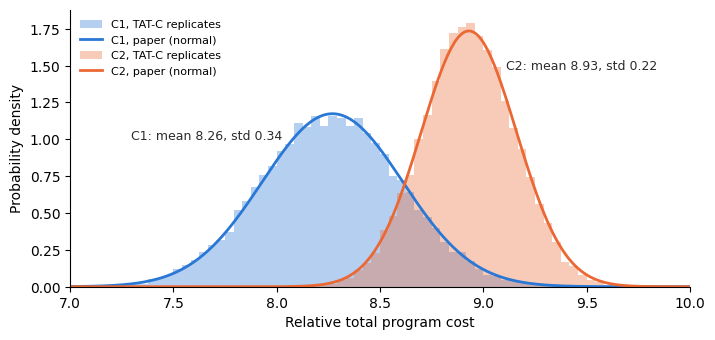

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.linspace(7, 10, 400)
paper = {"C1": (8.27, 0.34), "C2": (8.93, 0.23)}
for name, color, side in zip(CONSTELLATIONS, [BLUE, ORANGE], [-1, 1]):
    sample = wide["published counts", "common"][name]
    ax.hist(
        sample,
        bins=72,
        range=(7, 10),
        density=True,
        color=color,
        alpha=0.35,
        label=f"{name}, TAT-C replicates",
    )
    ax.plot(
        x,
        stats.norm.pdf(x, *paper[name]),
        color=color,
        lw=2,
        label=f"{name}, paper (normal)",
    )
    peak = stats.norm.pdf(paper[name][0], *paper[name])
    # labeled on the outer side of each peak, clear of the other distribution
    ax.annotate(
        f"{name}: mean {sample.mean():.2f}, std {sample.std():.2f}",
        (paper[name][0] + side * 0.6 * paper[name][1], 0.85 * peak),
        xytext=(side * 6, 0),
        textcoords="offset points",
        ha="left" if side > 0 else "right",
        color=INK,
        fontsize=9,
    )
ax.set(xlabel="Relative total program cost", ylabel="Probability density", xlim=(7, 10))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

## Test 4: Order of Costs

The probability that C2 costs more than C1 is, for the replicates, the share of replicates in which it does (`exceedance`, which counts ties as half). With common random numbers, both constellations draw the same scores in each replicate, so their costs are correlated by the configuration they share, as in eq. (15). With independent draws, they are not. The share of the variance of each constellation's cost, and of the difference of their costs, that each configuration's score causes is estimated with `attribute_variance` (by redrawing each score in turn, in 10,000 replicates of each design) and `Attribution.differences`, against the exact shares of the linear model (the square of each configuration's exposure, times its variance, over the variance of the cost).

In [7]:
from tatc.tradespace import attribute_variance, exceedance

key = {d.key: d.constellation for d in designs}
rows = []
for name, (_, table) in EVALUATIONS.items():
    for draws in ("common", "independent"):
        compared = exceedance(results[name, draws], "cost", designs)
        row = compared[
            (compared.design.map(key) == "C2") & (compared.other.map(key) == "C1")
        ].iloc[0]
        p = row.exceedance
        rows.append(
            {
                "costs": name,
                "draws": draws,
                "P(C2 > C1), expected": probability_exceeds(
                    *moments(table, correlated=draws == "common")
                )[1],
                "P(C2 > C1), replicates": p,
                "standard error": math.sqrt(p * (1 - p) / row.replicates),
                "mean difference": row["cost difference"],
            }
        )
print("paper: P(C2 > C1) = 0.978 (Fig. 3)")
display(pd.DataFrame(rows).set_index(["costs", "draws"]).round(4))

# the shares of the variance of each cost, and of the difference, that each configuration's score causes
attribution = attribute_variance(
    Study(space, build, published, replicates=10_000), ["cost"], designs
)
c1, c2 = (
    next(d for d in designs if d.constellation == name) for name in CONSTELLATIONS
)
difference = attribution.differences([(c2, c1)])
ba = exposures(PUBLISHED)
variance = np.array([VARIANCE_Q[c] for c in CONFIGURATIONS])
exact = {
    "C1": ba[0] ** 2 * variance,
    "C2": ba[1] ** 2 * variance,
    "C2 - C1": (ba[1] - ba[0]) ** 2 * variance,
}
rows = []
for label, shares in [
    ("C1", attribution.shares[attribution.shares.design == c1.key]),
    ("C2", attribution.shares[attribution.shares.design == c2.key]),
    ("C2 - C1", difference.shares),
]:
    for c, part in zip(CONFIGURATIONS, exact[label]):
        share = shares[shares.parameter == f"cost_risk.{c}"].iloc[0]
        rows.append(
            {
                "cost": label,
                "configuration": c,
                "exact share": part / exact[label].sum(),
                "TAT-C share": share.total,
                "standard error": share["total se"],
                "exact variance (millionths)": part * 1e6,
            }
        )
pd.DataFrame(rows).set_index(["cost", "configuration"]).round(3)

paper: P(C2 > C1) = 0.978 (Fig. 3)


P(C2 > C1), expected  P(C2 > C1), replicates  \
costs             draws                                                       
published counts  common                     0.9779                  0.9782   
                  independent                0.9491                  0.9475   
TAT-C deployments common                     0.9991                  0.9992   
                  independent                0.9948                  0.9959   

                               standard error  mean difference  
costs             draws                                         
published counts  common               0.0010           0.6647  
                  independent          0.0016           0.6690  
TAT-C deployments common               0.0002           1.0559  
                  independent          0.0005           1.0601

exact share  TAT-C share  standard error  \
cost    configuration                                             
C1      G4c                  0.164        0.164           0.003   
        L3e                  0.836        0.841           0.010   
        L4f                  0.000        0.000           0.000   
C2      G4c                  0.827        0.834           0.010   
        L3e                  0.000        0.000           0.000   
        L4f                  0.173        0.172           0.003   
C2 - C1 G4c                  0.041        0.041           0.001   
        L3e                  0.880        0.885           0.010   
        L4f                  0.080        0.079           0.001   

                       exact variance (millionths)  
cost    configuration                               
C1      G4c                              19035.599  
        L3e                              97082.544  
        L4f                                  0.000  
C2      G4c                              41957.088  
        L3e                                  0.000  
        L4f                               8800.728  
C2 - C1 G4c                               4470.893  
        L3e                              97082.544  
        L4f                               8800.728

`exceedance` reproduces the paper's probability: with the published counts and common random numbers, C2 costs more than C1 in 97.8% of the replicates (97.82% against 97.79% expected, with a standard error of 0.10%). With independent draws, it does in 94.8% (94.9% expected). With TAT-C's own deployments, C2 costs more in 99.92% of the replicates with common draws and 99.59% with independent ones (99.91% and 99.48% expected; the larger gap is 2.2 standard errors), higher than the paper's for L4f's counts (Test 2). The shares of variance that `attribute_variance` estimates match the exact shares within about one standard error (0.001 to 0.010).

The shares show why sharing G4c settles the order. G4c is 16% of the variance of C1's cost and 83% of C2's, but 4% of the variance of their difference: of its variance in C1 (19,000 millionths) and in C2 (42,000 millionths), 4,500 remain in the difference, since a costlier G4c raises both. The variance of the difference (110,000 millionths, against 167,000 if the costs were independent) is mostly L3e's, which only C1 flies. The joint distribution of the costs of the replicates (Fig. 3 of the paper), with the ellipse that holds 95% of the normal distribution of eqs. (6) and (8):

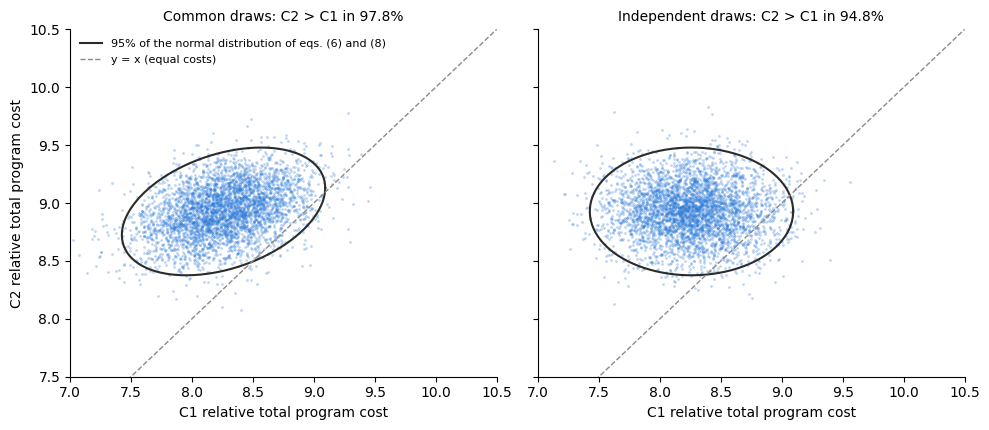

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
angles = np.linspace(0, 2 * np.pi, 200)
radius = math.sqrt(stats.chi2.ppf(0.95, 2))
for ax, draws in zip(axes, ("common", "independent")):
    sample = wide["published counts", draws].iloc[:4000]
    ax.scatter(sample.C1, sample.C2, s=4, color=BLUE, alpha=0.3, lw=0)
    mean, covariance = moments(PUBLISHED, correlated=draws == "common")
    ellipse = mean[:, None] + np.linalg.cholesky(covariance) @ (
        radius * np.array([np.cos(angles), np.sin(angles)])
    )
    ax.plot(
        *ellipse,
        color=INK,
        lw=1.5,
        label="95% of the normal distribution of eqs. (6) and (8)",
    )
    ax.plot(
        [7, 10.5], [7, 10.5], color=GRAY, lw=1, ls="--", label="y = x (equal costs)"
    )
    above = (
        wide["published counts", draws].C2 > wide["published counts", draws].C1
    ).mean()
    ax.set_title(f"{draws.capitalize()} draws: C2 > C1 in {above:.1%}", fontsize=10)
    ax.set(xlabel="C1 relative total program cost", xlim=(7, 10.5), ylim=(7.5, 10.5))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("C2 relative total program cost")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

With common random numbers (left), the replicates fill the ellipse of eq. (8), tilted by the configuration the constellations share, and 2.2% fall below the line *y* = *x*. With independent draws (right), each cost spreads as much as before but the ellipse is not tilted, and 5.2% fall below the line.

## Summary

| Test | Result |
| --- | --- |
| 1. Growth by maturity (`Triangular`, `Component`, `CostModel.correlation`) | Table I's means reproduced to its three decimals (existing components 1.0403 against 1.041, rounded up in the table); standard deviations equal to SciPy's; scores correlated by 0.5 correlate the growths by 0.486, so a configuration's variance is 1.3% below eq. (2) (a correlation of 0.514 gives 0.5) |
| 2. Production blocks (`DeploymentSchedule`, `SatelliteCost.block_size`) | Table III's launches, production of later units, and developments of both blocks of G4c reproduced to the month, with 0.375 of the unit in production at the end (0.37 published); over the study period (`sustained`, with a design life of each configuration), the published numbers of G4c (4.375 and 6.375 later units) and L3e reproduced, and C1's expected cost (8.261 against 8.259), but not those of L4f (4 developments against 2.9, 3.81 counted as Table III counts them) |
| 3. Constellation costs (`risk_space`, `CostModel.draw`, `Study`) | with the published counts, expected costs, standard deviations, and covariance of eqs. (6) and (8) within the sampling error of 20,000 replicates (means 8.26 and 8.93, standard deviations 0.34 and 0.22); TAT-C's deployments cost 8.26 and 9.32, as their counts predict |
| 4. Order of costs (`exceedance`, `attribute_variance`) | P(C2 > C1) of 97.8% with the published counts and common random numbers (97.8% published), 94.8% with independent draws (94.9% expected); 99.9% with TAT-C's deployments, whose L4f costs 0.39 more; G4c is 83% of C2's variance but 4% of the variance of the difference |

**Cost risk.** TAT-C's structured cost risk reproduces the paper's example. Configurations whose growth is drawn from scores, shared by common random numbers, give the constellations the covariance of eq. (8), and `exceedance` the probability of eq. (15), with no model of the covariance itself: what the constellations share is shared by drawing it once in each replicate. The same holds for configurations that share components or a common score, and for costs that are not linear in the growths (such as those of deployments with failures), which eq. (8) does not cover.

**Correlation.** `CostModel.correlation` is the correlation of the normal scores of components, from which their growths are drawn; the growths of Table I's skewed distributions are correlated slightly less (0.486 for 0.5). To reproduce a FRISK estimate that correlates costs by 0.5, use a correlation of about 0.514.

**Study periods.** The paper counts the costs of a sustained constellation over a fixed study period, including the share of the units in production at its end. A sustained `DeploymentSchedule` (`sustained=True`) does the same, and reproduces the paper's counts of G4c and L3e. A mission that is not sustained costs the satellites it launches by its end: here 1.7% less for C1 and 6.7% less for C2, whose fourth block of L4f is developed before the end but launched after it. The difference falls unevenly on alternatives, and so shifts the probability that one costs more than another (here, from 99.9% to 95.9%). The probability over the study period differs from the published one (97.8%) only because L4f's published counts cannot be derived from its schedule.